# Math to Deep Learning with PyTorch: Step-by-Step Notebooks
## Part 5 — Training Neural Networks End-to-End in PyTorch

### 📚 Series

| Part | Notebook |
|---|---|
| 1 | [Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-1-derivatives) |
| 2 | [Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func) |
| 3 | [Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-3-small-nn) |
| 4 | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz) |
| 5 | **Training Neural Networks End-to-End in PyTorch** |


## Goal

In the previous parts we studied:

- derivatives, gradients, and backpropagation;
- activation functions;
- building a small neural network;
- loss functions and optimizers.

Now we combine everything into a **complete model-training workflow**.

After this notebook, you should understand:

1. how to prepare data;
2. how to create a train/test split;
3. how to use `TensorDataset` and `DataLoader`;
4. why mini-batches are useful;
5. how to define a model;
6. how to write a training loop;
7. how to write an evaluation loop;
8. the difference between `model.train()` and `model.eval()`;
9. how to compute accuracy and a confusion matrix;
10. how to make predictions on new data;
11. how to save and restore a `state_dict`.

The final pipeline of the series is:

$$
\text{Data}
\rightarrow
\text{DataLoader}
\rightarrow
\text{Model}
\rightarrow
\text{Loss}
\rightarrow
\text{Backward}
\rightarrow
\text{Optimizer}
\rightarrow
\text{Evaluation}
\rightarrow
\text{Inference}
$$

## Setup

In [1]:
import copy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)

print("PyTorch version:", torch.__version__)

/home/oai/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-rv2xkpm7 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


PyTorch version: 2.10.0+cpu


# 1. Create a Simple Dataset


To avoid external dataset dependencies, we will generate a simple 2D binary-classification problem.

We create two groups:

```text
class 0 → roughly around (-1, -1)
class 1 → roughly around ( 1,  1)
```

This lets us study the **entire pipeline** without spending time on data downloading.

In [2]:
n_per_class = 250

class0 = torch.randn(n_per_class, 2) * 0.75 + torch.tensor([-1.0, -1.0])
class1 = torch.randn(n_per_class, 2) * 0.75 + torch.tensor([ 1.0,  1.0])

X = torch.cat([class0, class1], dim=0)
y = torch.cat([
    torch.zeros(n_per_class, 1),
    torch.ones(n_per_class, 1)
], dim=0)

permutation = torch.randperm(len(X))
X = X[permutation]
y = y[permutation]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([500, 2])
y shape: torch.Size([500, 1])


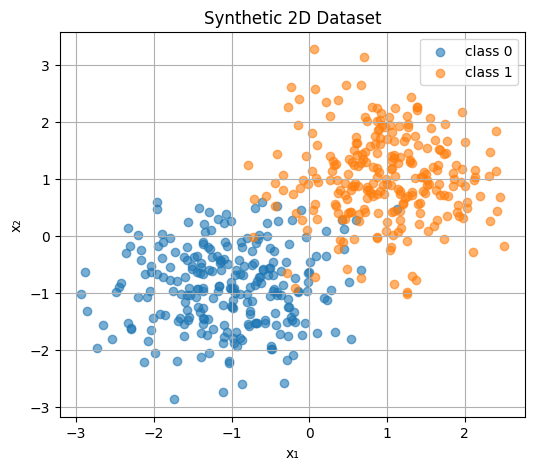

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X[y.squeeze()==0, 0], X[y.squeeze()==0, 1], alpha=0.6, label="class 0")
plt.scatter(X[y.squeeze()==1, 0], X[y.squeeze()==1, 1], alpha=0.6, label="class 1")
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Synthetic 2D Dataset")
plt.legend()
plt.grid(True)
plt.show()

# 2. Train/Test Split


A model should not be evaluated only on the data used for training.

So we split the data into:

- **train set** — used to update weights;
- **test set** — used only for evaluation.

Real projects often also include a separate validation set.

In [4]:
train_ratio = 0.8
train_size = int(len(X) * train_ratio)

X_train = X[:train_size]
y_train = y[:train_size]

X_test = X[train_size:]
y_test = y[train_size:]

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

Train: torch.Size([400, 2]) torch.Size([400, 1])
Test:  torch.Size([100, 2]) torch.Size([100, 1])


# 3. `TensorDataset` and `DataLoader`


`TensorDataset` combines features and targets.

`DataLoader`:

- splits the dataset into batches;
- can shuffle training data;
- provides a convenient iteration interface.

Typical code:

```python
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)
```

In [5]:
batch_size = 32

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

batch_X, batch_y = next(iter(train_loader))

print("One batch X shape:", batch_X.shape)
print("One batch y shape:", batch_y.shape)

One batch X shape: torch.Size([32, 2])
One batch y shape: torch.Size([32, 1])


# 4. Why Mini-Batches?


For large datasets, processing every sample at once can be expensive.

Instead, we use **mini-batches**:

```text
dataset
  ↓
batch 1
batch 2
batch 3
...
```

For each batch we can run:

```python
forward
loss
backward
optimizer.step()
```

This is mini-batch Gradient Descent.

# 5. Build the Neural Network


For binary classification, we use:

```text
2 inputs
   ↓
Linear(2, 8)
   ↓
ReLU
   ↓
Linear(8, 4)
   ↓
ReLU
   ↓
Linear(4, 1)
   ↓
logit
```

The last layer has **no sigmoid** because we use:

```python
BCEWithLogitsLoss
```

In [6]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 8),
            nn.ReLU(),
            nn.Linear(8, 4),
            nn.ReLU(),
            nn.Linear(4, 1)
        )

    def forward(self, x):
        return self.network(x)

model = BinaryClassifier()
print(model)

BinaryClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=4, bias=True)
    (3): ReLU()
    (4): Linear(in_features=4, out_features=1, bias=True)
  )
)


# 6. Check the Forward Pass


Before training, it is useful to verify:

- input shape;
- output shape;
- whether the forward pass runs correctly.

For a batch of `N` examples:

```text
input shape  = (N, 2)
output shape = (N, 1)
```

In [7]:
sample_logits = model(batch_X)

print("input shape: ", batch_X.shape)
print("output shape:", sample_logits.shape)
print("first 5 logits:")
print(sample_logits[:5])

input shape:  torch.Size([32, 2])
output shape: torch.Size([32, 1])
first 5 logits:
tensor([[0.1176],
        [0.0092],
        [0.1219],
        [0.1729],
        [0.1596]], grad_fn=<SliceBackward0>)


# 7. Loss and Optimizer


For binary classification:

```python
criterion = nn.BCEWithLogitsLoss()
```

We use Adam as the optimizer:

```python
torch.optim.Adam(...)
```

with:

```python
lr = 0.01
```

Adam is not always the best optimizer; it is simply convenient for this educational example.

In [8]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

sample_loss = criterion(sample_logits, batch_y)

print("sample loss:", sample_loss.item())

sample loss: 0.709979236125946


# 8. `model.train()` and `model.eval()`


A PyTorch model has two important modes:

```python
model.train()
model.eval()
```

### `model.train()`

Use during training.

### `model.eval()`

Use during validation, testing, and inference.

This becomes especially important for layers such as:

- `Dropout`;
- `BatchNorm`.

Even though our simple model does not require them, it is a good habit to use the modes correctly from the start.

# 9. One Training Epoch


One training epoch:

1. call `model.train()`;
2. take a batch;
3. `zero_grad()`;
4. forward pass;
5. compute loss;
6. `backward()`;
7. `step()`;
8. accumulate average loss.

In [9]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch_X, batch_y in loader:
        optimizer.zero_grad()

        logits = model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        batch_count = len(batch_X)
        total_loss += loss.item() * batch_count
        total_samples += batch_count

    return total_loss / total_samples

# 10. Evaluation Function


During evaluation:

- weights must not change;
- gradients are unnecessary.

So we use:

```python
model.eval()

with torch.no_grad():
    ...
```

In [10]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for batch_X, batch_y in loader:
            logits = model(batch_X)
            loss = criterion(logits, batch_y)

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).float()

            batch_count = len(batch_X)

            total_loss += loss.item() * batch_count
            total_correct += (predictions == batch_y).sum().item()
            total_samples += batch_count

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

# 11. Train the Model


Now we run many epochs.

For every epoch:

```text
train one epoch
      ↓
evaluate on test set
      ↓
store train/test loss
```

We will see the model gradually reduce its error.

In [11]:
torch.manual_seed(42)

model = BinaryClassifier()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 100

train_losses = []
test_losses = []
test_accuracies = []

for epoch in range(epochs):
    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    test_loss, test_accuracy = evaluate(
        model,
        test_loader,
        criterion
    )

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

    if (epoch + 1) % 20 == 0:
        print(
            f"epoch={epoch+1:3d} | "
            f"train_loss={train_loss:.4f} | "
            f"test_loss={test_loss:.4f} | "
            f"test_accuracy={test_accuracy:.3f}"
        )

epoch= 20 | train_loss=0.0958 | test_loss=0.0902 | test_accuracy=0.970
epoch= 40 | train_loss=0.0946 | test_loss=0.0871 | test_accuracy=0.970
epoch= 60 | train_loss=0.0913 | test_loss=0.0839 | test_accuracy=0.970
epoch= 80 | train_loss=0.0912 | test_loss=0.0812 | test_accuracy=0.970
epoch=100 | train_loss=0.0887 | test_loss=0.0804 | test_accuracy=0.970


# 12. Train/Test Loss Curves


Loss curves help us see whether learning is working.

We want to observe:

- whether train loss decreases;
- whether test loss decreases;
- whether the two curves begin to diverge strongly.

A strong divergence can be a sign of overfitting.

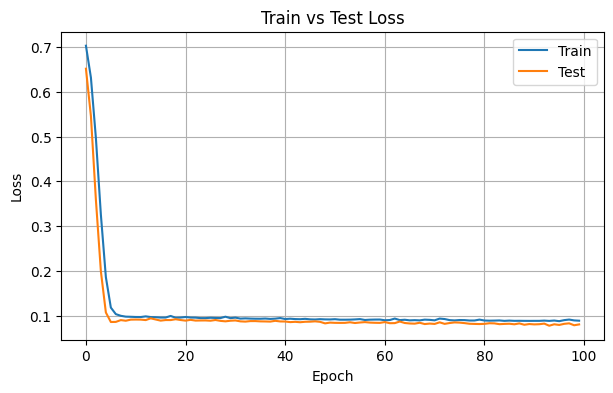

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Train")
plt.plot(test_losses, label="Test")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Test Loss")
plt.legend()
plt.grid(True)
plt.show()

# 13. Accuracy


For binary classification, logits are converted to probabilities:

```python
probability = sigmoid(logit)
```

Then:

```python
prediction = probability >= 0.5
```

Accuracy is:

$$
Accuracy=
\frac{\text{correct predictions}}
{\text{all predictions}}
$$

In [13]:
test_loss, test_accuracy = evaluate(model, test_loader, criterion)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss: 0.0804
Test accuracy: 0.97


In [14]:
def predict_dataset(model, X):
    model.eval()

    with torch.no_grad():
        logits = model(X)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

    return logits, probabilities, predictions

test_logits, test_probabilities, test_predictions = predict_dataset(
    model,
    X_test
)

# 14. Confusion Matrix


A Confusion Matrix shows more than overall accuracy:

| | Pred 0 | Pred 1 |
|---|---:|---:|
| True 0 | TN | FP |
| True 1 | FN | TP |

This becomes especially useful when classes are imbalanced.

In [15]:
true = y_test.squeeze().int()
pred = test_predictions.squeeze().int()

tn = ((true == 0) & (pred == 0)).sum().item()
fp = ((true == 0) & (pred == 1)).sum().item()
fn = ((true == 1) & (pred == 0)).sum().item()
tp = ((true == 1) & (pred == 1)).sum().item()

confusion = torch.tensor([
    [tn, fp],
    [fn, tp]
])

print(confusion)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

tensor([[43,  2],
        [ 1, 54]])
TN=43, FP=2, FN=1, TP=54


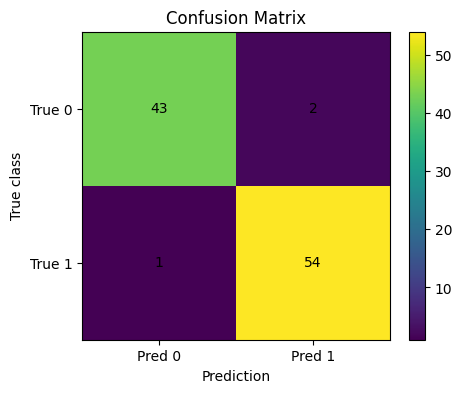

In [16]:
plt.figure(figsize=(5, 4))
plt.imshow(confusion.numpy())
plt.xticks([0, 1], ["Pred 0", "Pred 1"])
plt.yticks([0, 1], ["True 0", "True 1"])
plt.xlabel("Prediction")
plt.ylabel("True class")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, int(confusion[i, j]), ha="center", va="center")

plt.colorbar()
plt.show()

# 15. Visualizing the Decision Boundary


Because the data is two-dimensional, we can visualize which parts of the plane the model assigns to class 0 or class 1.

This is a useful way to see what the neural network actually learned.

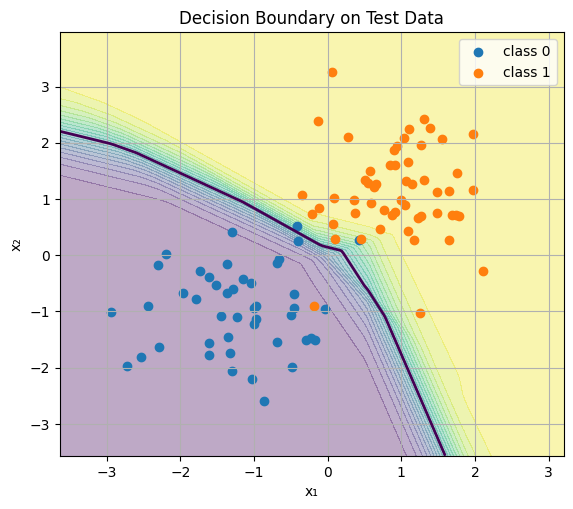

In [17]:
x1_min = X[:, 0].min().item() - 0.7
x1_max = X[:, 0].max().item() + 0.7
x2_min = X[:, 1].min().item() - 0.7
x2_max = X[:, 1].max().item() + 0.7

grid_x1 = torch.linspace(x1_min, x1_max, 160)
grid_x2 = torch.linspace(x2_min, x2_max, 160)

mesh_x1, mesh_x2 = torch.meshgrid(
    grid_x1,
    grid_x2,
    indexing="xy"
)

grid_points = torch.stack(
    [mesh_x1.reshape(-1), mesh_x2.reshape(-1)],
    dim=1
)

with torch.no_grad():
    grid_probabilities = torch.sigmoid(
        model(grid_points)
    ).reshape(mesh_x1.shape)

plt.figure(figsize=(6.5, 5.5))
plt.contourf(
    mesh_x1.numpy(),
    mesh_x2.numpy(),
    grid_probabilities.numpy(),
    levels=20,
    alpha=0.35
)
plt.contour(
    mesh_x1.numpy(),
    mesh_x2.numpy(),
    grid_probabilities.numpy(),
    levels=[0.5],
    linewidths=2
)

plt.scatter(
    X_test[y_test.squeeze()==0, 0],
    X_test[y_test.squeeze()==0, 1],
    label="class 0"
)
plt.scatter(
    X_test[y_test.squeeze()==1, 0],
    X_test[y_test.squeeze()==1, 1],
    label="class 1"
)

plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("Decision Boundary on Test Data")
plt.legend()
plt.grid(True)
plt.show()

# 16. Prediction on New Data


After training, we can pass **new points** that the model has never seen.

The standard pattern is:

```python
model.eval()

with torch.no_grad():
    logits = model(new_X)
    probabilities = torch.sigmoid(logits)
```

In [18]:
new_X = torch.tensor([
    [-2.0, -1.5],
    [ 0.0,  0.0],
    [ 1.5,  2.0],
])

model.eval()

with torch.no_grad():
    new_logits = model(new_X)
    new_probabilities = torch.sigmoid(new_logits)
    new_predictions = (new_probabilities >= 0.5).int()

for point, probability, prediction in zip(
    new_X,
    new_probabilities,
    new_predictions
):
    print(
        f"x={point.tolist()} | "
        f"P(class=1)={probability.item():.4f} | "
        f"prediction={prediction.item()}"
    )

x=[-2.0, -1.5] | P(class=1)=0.0000 | prediction=0
x=[0.0, 0.0] | P(class=1)=0.3185 | prediction=0
x=[1.5, 2.0] | P(class=1)=1.0000 | prediction=1


# 17. `state_dict`: Saving Model Parameters


Model parameters are stored in:

```python
model.state_dict()
```

For real file saving:

```python
torch.save(model.state_dict(), "model.pt")
```

and loading:

```python
model.load_state_dict(torch.load("model.pt"))
```

In this notebook we demonstrate copying a `state_dict` without requiring an external file.

In [19]:
saved_state = copy.deepcopy(model.state_dict())

print("Saved parameter keys:")
for key in saved_state:
    print(key, tuple(saved_state[key].shape))

restored_model = BinaryClassifier()
restored_model.load_state_dict(saved_state)
restored_model.eval()

with torch.no_grad():
    original_output = model(X_test[:5])
    restored_output = restored_model(X_test[:5])

print(
    "\nOutputs identical after restoring:",
    torch.allclose(original_output, restored_output)
)

Saved parameter keys:
network.0.weight (8, 2)
network.0.bias (8,)
network.2.weight (4, 8)
network.2.bias (4,)
network.4.weight (1, 4)
network.4.bias (1,)

Outputs identical after restoring: True


# 18. The Full PyTorch Pipeline in One Place


This is the reusable high-level structure:

```text
1. Prepare data
2. Split data
3. Create Dataset/DataLoader
4. Define model
5. Define loss
6. Define optimizer
7. Train
8. Validate
9. Evaluate metrics
10. Inference
```

A large number of PyTorch projects are built around this same structure.

In [20]:
# Compact end-to-end template

# 1. Dataset / DataLoader
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# 2. Model
model = BinaryClassifier()

# 3. Loss + optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

# 4. Training
for epoch in range(5):
    model.train()

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        logits = model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

# 5. Evaluation
model.eval()

with torch.no_grad():
    logits = model(X_test)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).float()

accuracy = (predictions == y_test).float().mean()

print("Accuracy:", accuracy.item())

Accuracy: 0.9700000286102295


# Checks

# 19. Small Exercises


### Exercise 1
Change:

```python
batch_size = 32
```

to `8`, `16`, and `64`.

Compare training speed and stability.

### Exercise 2
Replace Adam with:

```python
torch.optim.SGD(model.parameters(), lr=0.05)
```

### Exercise 3
Add another hidden layer.

### Exercise 4
Change the classification threshold:

```python
0.3
0.5
0.7
```

and compare the confusion matrices.

### Exercise 5
Add `Dropout` and observe why `train()` / `eval()` become especially important.

# 20. Final Series Cheat Sheet


| Stage | Typical PyTorch code |
|---|---|
| dataset | `TensorDataset(X, y)` |
| batches | `DataLoader(...)` |
| model | `class Model(nn.Module)` |
| forward | `model(X)` |
| loss | `criterion(pred, y)` |
| clear gradients | `optimizer.zero_grad()` |
| gradients | `loss.backward()` |
| update | `optimizer.step()` |
| train mode | `model.train()` |
| eval mode | `model.eval()` |
| disable gradients | `torch.no_grad()` |
| probabilities | `torch.sigmoid(logits)` |
| parameters | `model.state_dict()` |

The core pattern of the whole series is:

$$
\boxed{
\text{Forward}
\rightarrow
\text{Loss}
\rightarrow
\text{Backward}
\rightarrow
\text{Update}
\rightarrow
\text{Evaluate}
}
$$

# Series Complete 🎉


We have completed the full journey:

1. **Derivatives & Gradients**
2. **Activation Functions & Chain Rule**
3. **Small Neural Networks**
4. **Loss Functions & Optimization**
5. **End-to-End Training**

Now code like:

```python
loss.backward()
optimizer.step()
```

is no longer "magic" — we understand the mathematics and the training logic behind it.

A natural next level could include:

- regularization;
- Dropout;
- Batch Normalization;
- CNNs;
- RNN/LSTMs;
- Transformers;
- custom datasets;
- GPU training;
- experiment tracking.


### 📚 Complete Series

| Part | Notebook |
|---|---|
| 1 | [Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-1-derivatives) |
| 2 | [Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func) |
| 3 | [Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-3-small-nn) |
| 4 | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz) |
| 5 | **Training Neural Networks End-to-End in PyTorch** |

## Found this notebook useful? An upvote 👍 would be greatly appreciated!